In [1]:
!pip install -q yfinance arch xgboost scikit-learn

In [2]:

import yfinance as yf
import pandas as pd
import numpy as np

tickers = ["NVDA", "AAPL", "MSFT", "TSLA", "SPY"]

# Fixed historical period for consistent evaluation
start_date = "2018-01-01"
end_date = "2026-10-01"

price_data = {}

for ticker in tickers:
    try:
        df = yf.download(
            ticker,
            start=start_date,
            end=end_date,
            auto_adjust=True,
            progress=False
        )

        if df.empty:
            print(f"No data available: {ticker}")
            continue

        if isinstance(df.columns, pd.MultiIndex):
            df.columns = df.columns.get_level_values(0)

        price_data[ticker] = df["Close"].dropna()

        print(f"{ticker}: {len(price_data[ticker])} observations")

    except Exception as e:
        print(f"Error downloading {ticker}: {e}")


NVDA: 2198 observations
AAPL: 2198 observations
MSFT: 2198 observations
TSLA: 2198 observations
SPY: 2198 observations


In [3]:

from arch import arch_model
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error

HORIZON = 5

def prepare_data(prices):
    """Create historical features and future variance targets."""

    r = np.log(prices / prices.shift(1)).dropna() * 100

    X = pd.DataFrame(index=r.index)

    for window in [5, 10, 20, 60]:
        X[f"var_{window}d"] = r.pow(2).rolling(window).mean()
        X[f"return_{window}d"] = r.rolling(window).sum()

    X["abs_return_1d"] = r.abs()
    X["return_1d"] = r
    X["negative_return_1d"] = (r < 0).astype(int)

    # Next five days' mean squared percentage returns
    future = pd.concat(
        [r.shift(-i).pow(2) for i in range(1, HORIZON + 1)],
        axis=1
    )

    X["target"] = future.mean(axis=1)
    X.loc[X.index[-HORIZON:], "target"] = np.nan

    return r, X.dropna()


def build_xgboost():
    """Fixed model specification chosen during development."""

    return XGBRegressor(
        n_estimators=100,
        max_depth=2,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=10,
        min_child_weight=10,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=2
    )


In [4]:

from sklearn.metrics import mean_squared_error

EPSILON = 1e-6

def evaluate_ticker(ticker, prices):

    returns_pct, dataset = prepare_data(prices)

    n = len(dataset)
    train_end = int(n * 0.70)
    test_start = int(n * 0.85)

    feature_cols = [
        c for c in dataset.columns if c != "target"
    ]

    # Exclude labels that reach the next period
    train = dataset.iloc[:train_end - HORIZON]

    # Fixed final evaluation portion
    test = dataset.iloc[test_start::HORIZON]

    if len(train) < 250 or len(test) < 10:
        raise ValueError("Insufficient training or test data")

    model = build_xgboost()

    model.fit(
        train[feature_cols],
        np.log(train["target"] + EPSILON)
    )

    records = []

    for date, row in test.iterrows():

        # Historical information available through date
        history = returns_pct.loc[:date]

        # Historical variance baseline
        baseline_var = history.iloc[-20:].var(ddof=1)

        # GARCH forecast
        garch = arch_model(
            history,
            mean="Constant",
            vol="GARCH",
            p=1,
            q=1,
            dist="t"
        )

        fit = garch.fit(
            disp="off",
            show_warning=False
        )

        garch_var = fit.forecast(
            horizon=HORIZON
        ).variance.iloc[-1].mean()

        # XGBoost forecast
        xgb_log = model.predict(
            row[feature_cols].to_frame().T
        )[0]

        xgb_var = np.exp(xgb_log) - EPSILON

        records.append({
            "Ticker": ticker,
            "Date": date,
            "Actual": row["target"],
            "Baseline": max(baseline_var, EPSILON),
            "GARCH": max(garch_var, EPSILON),
            "XGBoost": max(xgb_var, EPSILON)
        })

    return pd.DataFrame(records)


all_forecasts = []

for ticker, prices in price_data.items():
    print(f"Evaluating {ticker}...")

    try:
        result = evaluate_ticker(ticker, prices)
        all_forecasts.append(result)

    except Exception as e:
        print(f"Failed for {ticker}: {e}")

if not all_forecasts:
    raise RuntimeError("No tickers were evaluated successfully.")

forecasts_df = pd.concat(all_forecasts, ignore_index=True)

print("Completed forecasts:", len(forecasts_df))
display(forecasts_df.head())


Evaluating NVDA...
Evaluating AAPL...
Evaluating MSFT...
Evaluating TSLA...
Evaluating SPY...
Completed forecasts: 320


,Ticker,Date,Actual,Baseline,GARCH,XGBoost
0,NVDA,2025-06-16,1.776281,3.141620,5.555253,2.975700
1,NVDA,2025-06-24,6.072698,3.008293,5.092856,2.975700
2,NVDA,2025-07-01,2.620244,2.982648,6.312807,5.128946
3,NVDA,2025-07-09,3.383768,2.912149,5.440335,3.621219
4,NVDA,2025-07-16,2.582299,2.891859,5.539668,3.517362


In [5]:

from sklearn.metrics import mean_absolute_error, mean_squared_error

leaderboard = []

for ticker, group in forecasts_df.groupby("Ticker"):

    actual_vol = np.sqrt(group["Actual"].to_numpy() * 252)

    for model_name in ["Baseline", "GARCH", "XGBoost"]:

        predicted_vol = np.sqrt(
            group[model_name].to_numpy() * 252
        )

        mae = mean_absolute_error(actual_vol, predicted_vol)

        rmse = np.sqrt(mean_squared_error(
            actual_vol, predicted_vol
        ))

        bias = np.mean(predicted_vol - actual_vol)

        leaderboard.append({
            "Ticker": ticker,
            "Model": model_name,
            "MAE": mae,
            "RMSE": rmse,
            "Bias": bias
        })

leaderboard_df = pd.DataFrame(leaderboard)

display(
    leaderboard_df.sort_values(
        ["Ticker", "MAE"]
    ).round(3)
)


,Ticker,Model,MAE,RMSE,Bias
2,AAPL,XGBoost,9.111,11.735,-0.824
1,AAPL,GARCH,10.055,12.344,4.497
0,AAPL,Baseline,10.142,12.402,1.713
5,MSFT,XGBoost,10.970,18.351,0.612
4,MSFT,GARCH,11.503,17.635,3.138
3,MSFT,Baseline,12.799,19.520,2.124
8,NVDA,XGBoost,10.005,12.600,0.105
6,NVDA,Baseline,11.351,13.565,1.670
7,NVDA,GARCH,12.199,14.846,7.698
11,SPY,XGBoost,3.275,4.268,-0.198


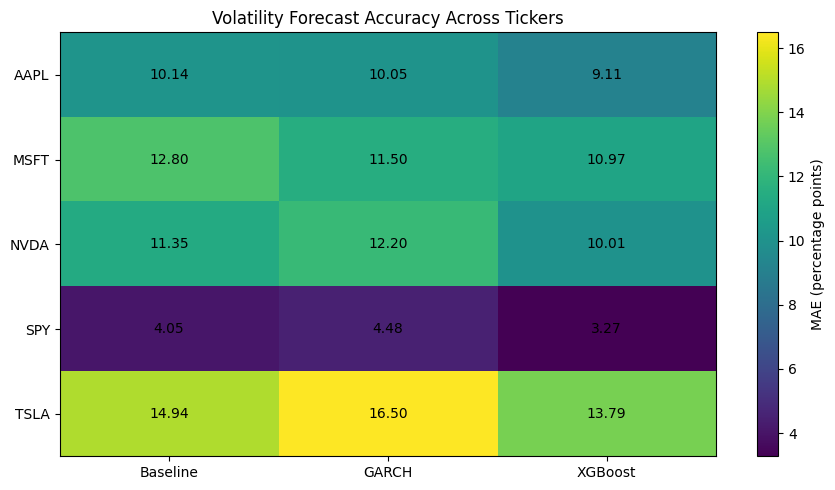

In [6]:

import matplotlib.pyplot as plt

heatmap_data = leaderboard_df.pivot(
    index="Ticker",
    columns="Model",
    values="MAE"
)

fig, ax = plt.subplots(figsize=(9, 5))

im = ax.imshow(heatmap_data.values, aspect="auto")

ax.set_xticks(range(len(heatmap_data.columns)))
ax.set_xticklabels(heatmap_data.columns)

ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index)

for i in range(len(heatmap_data.index)):
    for j in range(len(heatmap_data.columns)):
        ax.text(
            j, i,
            f"{heatmap_data.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.colorbar(im, ax=ax, label="MAE (percentage points)")
plt.title("Volatility Forecast Accuracy Across Tickers")
plt.tight_layout()
plt.show()


In [7]:

import numpy as np
import pandas as pd

# QLIKE: lower values indicate better variance forecasts
def qlike(actual_var, predicted_var):
    actual_var = np.asarray(actual_var)
    predicted_var = np.maximum(
        np.asarray(predicted_var), 1e-8
    )

    return np.mean(
        actual_var / predicted_var
        + np.log(predicted_var)
    )

qlike_results = []

for ticker, group in forecasts_df.groupby("Ticker"):

    for model in ["Baseline", "GARCH", "XGBoost"]:

        score = qlike(
            group["Actual"],
            group[model]
        )

        qlike_results.append({
            "Ticker": ticker,
            "Model": model,
            "QLIKE": score
        })

qlike_df = pd.DataFrame(qlike_results)

display(
    qlike_df.sort_values(
        ["Ticker", "QLIKE"]
    ).round(4)
)


,Ticker,Model,QLIKE
1,AAPL,GARCH,1.8862
0,AAPL,Baseline,1.9916
2,AAPL,XGBoost,2.0032
4,MSFT,GARCH,2.2233
3,MSFT,Baseline,2.4297
5,MSFT,XGBoost,2.4658
8,NVDA,XGBoost,2.6600
7,NVDA,GARCH,2.6730
6,NVDA,Baseline,2.6799
11,SPY,XGBoost,0.4776


In [8]:

import yfinance as yf
import numpy as np
from arch import arch_model

# Let the user choose any ticker
ticker = input("Enter a stock ticker (e.g. AMD, VOO, META): ")
ticker = ticker.strip().upper()

# Download historical prices
data = yf.download(
    ticker,
    period="5y",
    auto_adjust=True,
    progress=False
)

if data.empty:
    raise ValueError(f"No market data found for {ticker}")

# Handle yfinance column formats
if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)

prices = data["Close"].dropna()

if len(prices) < 100:
    raise ValueError("Not enough historical data")

# Calculate daily returns
returns_pct = np.log(prices / prices.shift(1)).dropna() * 100

# Historical volatility
historical_vol = returns_pct.iloc[-20:].std() * np.sqrt(252)

# Fit GARCH
model = arch_model(
    returns_pct,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="t"
)

fit = model.fit(disp="off")

# Five-day volatility forecast
forecast = fit.forecast(horizon=5)
forecast_var = forecast.variance.iloc[-1].mean()

garch_vol = np.sqrt(forecast_var * 252)

print(f"\nStock: {ticker}")
print(f"Historical volatility: {historical_vol:.2f}%")
print(f"5-day GARCH forecast: {garch_vol:.2f}%")


Enter a stock ticker (e.g. AMD, VOO, META): VOO

Stock: VOO
Historical volatility: 10.67%
5-day GARCH forecast: 13.13%


In [9]:

import numpy as np
from sklearn.metrics import mean_absolute_error

# Prepare historical features for selected ticker
r, dataset = prepare_data(prices)

feature_cols = [
    col for col in dataset.columns if col != "target"
]

# Train XGBoost using historical labeled observations
model_xgb = build_xgboost()

epsilon = 1e-6

model_xgb.fit(
    dataset[feature_cols],
    np.log(dataset["target"] + epsilon)
)

# Create features for the most recent trading day
# without requiring future outcomes
latest_features = dataset[feature_cols].iloc[-1]

# IMPORTANT: Recalculate latest features from all returns,
# including dates without a known future target
feature_data = pd.DataFrame(index=r.index)

for window in [5, 10, 20, 60]:
    feature_data[f"var_{window}d"] = (
        r.pow(2).rolling(window).mean()
    )
    feature_data[f"return_{window}d"] = (
        r.rolling(window).sum()
    )

feature_data["abs_return_1d"] = r.abs()
feature_data["return_1d"] = r
feature_data["negative_return_1d"] = (
    r < 0
).astype(int)

latest_features = (
    feature_data[feature_cols]
    .dropna()
    .iloc[[-1]]
)

# Predict log future variance
predicted_log_var = model_xgb.predict(
    latest_features
)[0]

# Convert back to variance
predicted_var = max(
    np.exp(predicted_log_var) - epsilon,
    1e-8
)

# Annualized five-day volatility forecast (%)
xgb_vol = np.sqrt(predicted_var * 252)

print(f"\nVOLATILITYLAB — {ticker}")
print("--------------------------------")
print(f"20-day Historical: {historical_vol:.2f}%")
print(f"5-day GARCH:       {garch_vol:.2f}%")
print(f"5-day XGBoost:     {xgb_vol:.2f}%")



VOLATILITYLAB — VOO
--------------------------------
20-day Historical: 10.67%
5-day GARCH:       13.13%
5-day XGBoost:     13.40%


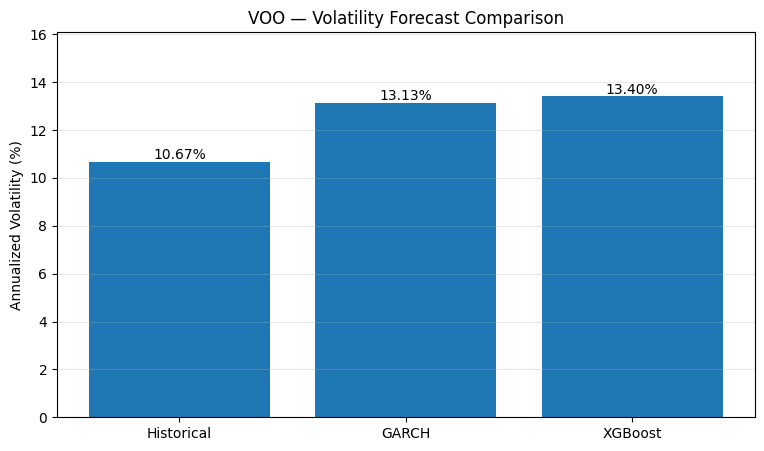

In [10]:

import matplotlib.pyplot as plt

model_names = [
    "Historical",
    "GARCH",
    "XGBoost"
]

vol_values = [
    historical_vol,
    garch_vol,
    xgb_vol
]

plt.figure(figsize=(9, 5))

bars = plt.bar(model_names, vol_values)

for bar, value in zip(bars, vol_values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.title(f"{ticker} — Volatility Forecast Comparison")
plt.ylabel("Annualized Volatility (%)")
plt.ylim(0, max(vol_values) * 1.2)
plt.grid(axis="y", alpha=0.3)
plt.show()
